# Curly-FM — Lotka-Volterra Results

**Auteur** : Krsto Petrovic  
**Date** : 22 avril 2026  
**Objectif** : Présentation des résultats du training Curly-FM sur le dataset Lotka-Volterra

---

## Sommaire

1. **Données & Vitesses exactes** — Calcul du drift SDE analytique
2. **Architecture du modèle** — Stage 1 (geodesic_net) + Stage 2 (velocity net)
3. **Courbes de training** — Loss & validation metrics
4. **Trajectoires prédites** — Comparaison predicted vs ground truth
5. **Espace de phase** — Champ de vitesses appris
6. **Résumé des métriques** — Tableau final

In [1]:
# ============================================================
# Setup — imports et configuration
# ============================================================
import numpy as np
import torch
import matplotlib.pyplot as plt
import matplotlib
import pandas as pd
import os, sys

# Fix PyTorch 2.6 checkpoint loading
_orig_torch_load = torch.load
def _patched_load(*args, **kwargs):
    kwargs['weights_only'] = False
    return _orig_torch_load(*args, **kwargs)
torch.load = _patched_load

# Project paths
PROJECT_DIR = os.path.abspath(os.path.join(os.getcwd(), '..'))
sys.path.insert(0, PROJECT_DIR)
sys.path.insert(0, os.path.join(PROJECT_DIR, 'src'))

DATA_DIR = os.path.join(PROJECT_DIR, 'Answer')
CKPT_DIR = os.path.join(PROJECT_DIR, 'logs', 'train', 'runs', '2026-04-29_11-43-17')
CKPT_PATH = os.path.join(CKPT_DIR, 'checkpoints', 'last.ckpt')
CSV_PATH = os.path.join(CKPT_DIR, 'csv', 'version_0', 'metrics.csv')

from models.components.resnet import ResNetMLP
from torchdyn.core import NeuralODE
from torchcfm.utils import torch_wrapper

# Style
plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor': '#fafafa',
    'axes.grid': True,
    'grid.alpha': 0.3,
    'font.size': 12,
    'axes.titlesize': 14,
    'axes.labelsize': 12,
})

print(f'Project: {PROJECT_DIR}')
print(f'Checkpoint: {CKPT_PATH}')
print(f'CSV: {CSV_PATH}')
print('Setup OK')


Project: C:\Users\dell\Desktop\EURECOM\S8\curly-flow-matching
Checkpoint: C:\Users\dell\Desktop\EURECOM\S8\curly-flow-matching\logs\train\runs\2026-04-29_11-43-17\checkpoints\last.ckpt
CSV: C:\Users\dell\Desktop\EURECOM\S8\curly-flow-matching\logs\train\runs\2026-04-29_11-43-17\csv\version_0\metrics.csv
Setup OK


---

## 1. Données & Vitesses exactes (Drift SDE)

Le dataset Lotka-Volterra contient **100 particules** observées à **5 snapshots temporels** dans un espace 2D (proies $x$, prédateurs $y$).

Les vitesses exactes sont calculées via le **drift analytique** du système SDE :

$$\frac{dx}{dt} = \alpha x - \beta x y \qquad \frac{dy}{dt} = \gamma x y - \delta y$$

Avec les paramètres : $\alpha=1,\ \beta=0.4,\ \gamma=0.1,\ \delta=0.4,\ \Delta t=2.0$

> **Note** : On utilise l'option 1 (SDE exacte), pas une approximation par différences finies.

In [2]:
# ============================================================
# 1. Chargement des données et vérification des vitesses
# ============================================================

positions = np.load(os.path.join(DATA_DIR, 'lv_train'), allow_pickle=True)
velocities = np.load(os.path.join(DATA_DIR, 'lv_train_velocities.npy'))

print(f'Positions  : {positions.shape}  →  (n_particles, n_timesteps, dim)')
print(f'Velocities : {velocities.shape}  →  (n_particles, n_timesteps, dim)')
print(f'\nStats positions  — mean: {positions.mean():.3f}, std: {positions.std():.3f}')
print(f'Stats velocities — mean: {velocities.mean():.3f}, std: {velocities.std():.3f}')


Positions  : (100, 5, 2)  →  (n_particles, n_timesteps, dim)
Velocities : (100, 5, 2)  →  (n_particles, n_timesteps, dim)

Stats positions  — mean: 3.115, std: 1.849
Stats velocities — mean: 0.000, std: 2.790


In [3]:
# Verification : recalcul du drift et comparaison
def lotka_volterra_drift(xt, dt=2.0):
    """Drift analytique LV : dx = ax - bxy, dy = gxy - dy"""
    ALPHA, BETA, GAMMA, DELTA = 1.0, 0.4, 0.1, 0.4
    x, y = xt[..., 0], xt[..., 1]
    dx = ALPHA * x - BETA * x * y
    dy = GAMMA * x * y - DELTA * y
    return torch.stack([dx, dy], dim=-1) * dt

# Recalcul
pos_t = torch.tensor(positions, dtype=torch.float32)
vel_check = lotka_volterra_drift(pos_t, dt=2.0).numpy()
diff = np.abs(vel_check - velocities).max()
print(f'Max difference entre vitesses sauvees et recalculees : {diff:.2e}')
print('Verification OK !' if diff < 1e-5 else 'ERREUR : vitesses differentes !')

Max difference entre vitesses sauvees et recalculees : 0.00e+00
Verification OK !


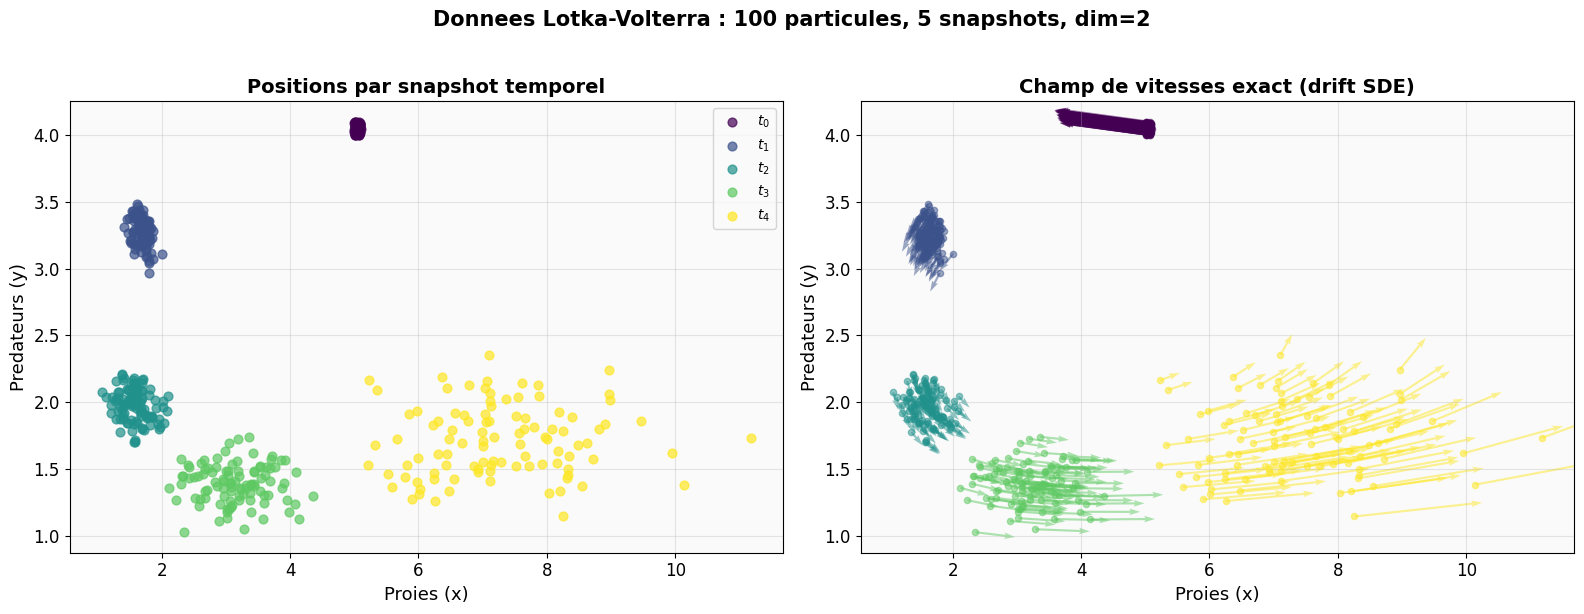

In [4]:
# Visualisation des données brutes : positions + champ de vitesses exact
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# --- Panel gauche : Positions par timestep ---
ax = axes[0]
colors_t = plt.cm.viridis(np.linspace(0, 1, positions.shape[1]))
for ti in range(positions.shape[1]):
    ax.scatter(positions[:, ti, 0], positions[:, ti, 1],
               c=[colors_t[ti]], s=40, alpha=0.7, label=f'$t_{ti}$', zorder=3)
ax.set_xlabel('Proies (x)', fontsize=13)
ax.set_ylabel('Predateurs (y)', fontsize=13)
ax.set_title('Positions par snapshot temporel', fontsize=14, fontweight='bold')
ax.legend(fontsize=10)

# --- Panel droit : Champ de vitesses exact ---
ax = axes[1]
for ti in range(positions.shape[1]):
    ax.quiver(positions[:, ti, 0], positions[:, ti, 1],
              velocities[:, ti, 0], velocities[:, ti, 1],
              color=colors_t[ti], alpha=0.5, scale=50, width=0.003)
    ax.scatter(positions[:, ti, 0], positions[:, ti, 1],
               c=[colors_t[ti]], s=20, alpha=0.5, zorder=3)
ax.set_xlabel('Proies (x)', fontsize=13)
ax.set_ylabel('Predateurs (y)', fontsize=13)
ax.set_title('Champ de vitesses exact (drift SDE)', fontsize=14, fontweight='bold')

plt.suptitle('Donnees Lotka-Volterra : 100 particules, 5 snapshots, dim=2',
             fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

---

## 2. Architecture du modèle Curly-FM

Le modèle est composé de **deux réseaux** (MLP à 3 couches cachées, SELU) :

| Réseau | Input | Output | Rôle |
|---|---|---|---|
| `geodesic_net` | $(x_0, x_1, t) \in \mathbb{R}^5$ | $\mathbb{R}^2$ | Apprend les **interpolations courbes** (neural interpolant) |
| `net` (velocity) | $(x_t, t) \in \mathbb{R}^3$ | $\mathbb{R}^2$ | Apprend le **champ de vitesses** |

### Formule de l'interpolation :
$$\mu_t(x_0, x_1) = (1-t) \cdot x_0 + t \cdot x_1 + t(1-t) \cdot \text{geodesic\_net}(x_0, x_1, t)$$

Le terme $t(1-t) \cdot g(\cdot)$ ajoute une **courbure** à l'interpolation linéaire, ce qui permet au modèle d'apprendre des trajectoires qui respectent la dynamique du système.

### Pipeline d'entraînement :
1. **Couplage OT** : Les particules sources et cibles sont appariées par transport optimal (Hungarian algorithm)
2. **Stage 1** : Loss géodésique = MSE + cosine similarity entre $\dot{\mu}_t$ et $u_t$ (vitesse kNN)
3. **Stage 2** : Loss vélocité = MSE entre le velocity net et $\dot{\mu}_t$ détaché

In [5]:
# ============================================================
# 2. Chargement du modele entraine
# ============================================================

ckpt = torch.load(CKPT_PATH)
state_dict = ckpt['state_dict']

# Velocity net (Stage 2) — ResNetMLP, dim=2, time_varying=True, width=256, 4 blocks
vel_net = ResNetMLP(dim=2, out_dim=2, width=256, time_varying=True, num_blocks=4)
vel_state = {k.replace('vel_model.', '', 1): v for k, v in state_dict.items()
             if k.startswith('vel_model.')}
vel_net.load_state_dict(vel_state)
vel_net.eval()

# Geodesic net (Stage 1) — ResNetMLP, dim=4, time_varying=True, width=256, 4 blocks
geo_net = ResNetMLP(dim=4, out_dim=2, width=256, time_varying=True, num_blocks=4)
geo_state = {k.replace('geo_model.', '', 1): v for k, v in state_dict.items()
             if k.startswith('geo_model.')}
geo_net.load_state_dict(geo_state)
geo_net.eval()

# Compter les parametres
n_params_vel = sum(p.numel() for p in vel_net.parameters())
n_params_geo = sum(p.numel() for p in geo_net.parameters())

print(f'Velocity net    : {n_params_vel:,} parametres')
print(f'Geodesic net    : {n_params_geo:,} parametres')
print(f'Total           : {n_params_vel + n_params_geo:,} parametres')
print(f'\nCheckpoint      : epoch {ckpt.get("epoch", "?")}')
print(f'Modeles charges avec succes !')


Velocity net    : 527,874 parametres
Geodesic net    : 528,386 parametres
Total           : 1,056,260 parametres

Checkpoint      : epoch 3000
Modeles charges avec succes !


C:\Users\dell\AppData\Local\Programs\Python\Python310\lib\site-packages\torch\serialization.py:2190: FutureWarning: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
  result = unpickler.load()


---

## 3. Courbes de training

Le training se déroule en **deux phases** :
- **Stage 1** (epochs 0–1499) : entraînement du réseau géodésique (geodesic net)
- **Stage 2** (epochs 1500–2999) : entraînement du réseau de vitesses (velocity net)

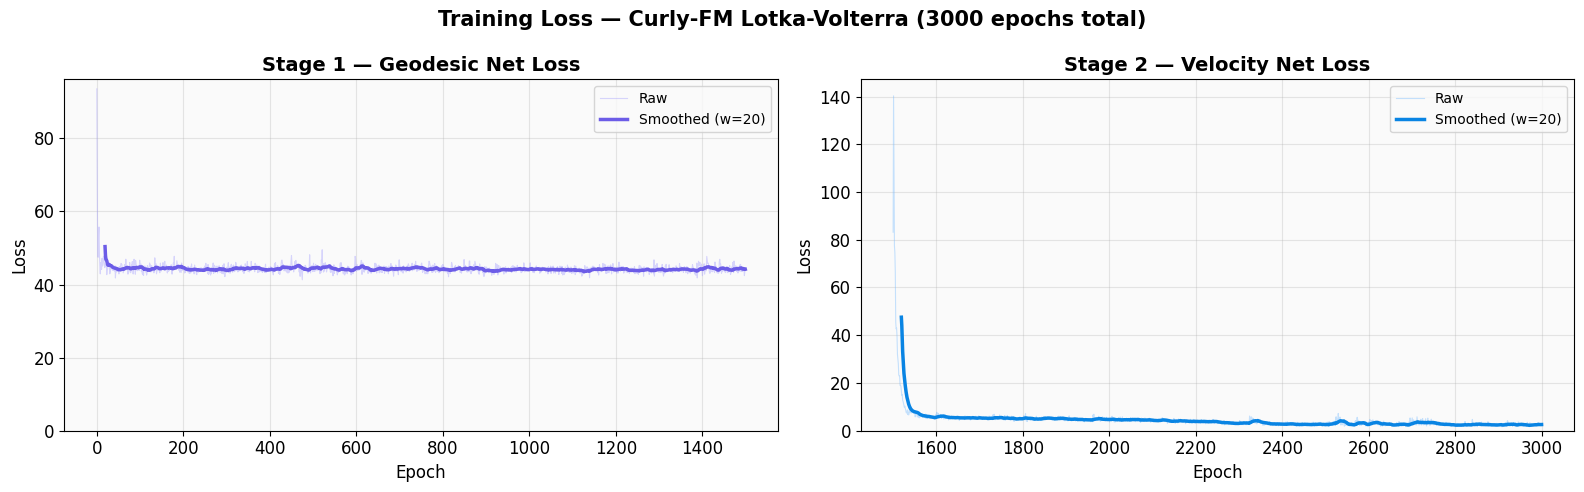

Geo  — initiale: 93.518, finale: 44.255
Vel  — initiale: 83.163, finale: 2.680


In [6]:
# ============================================================
# 3a. Courbes de loss (Stage 1: Geodesic, Stage 2: Velocity)
# ============================================================
df = pd.read_csv(CSV_PATH)

geo_loss = df[df['train_geonet/loss'].notna()][['epoch', 'train_geonet/loss']].copy()
vel_loss = df[df['train_vel/loss'].notna()][['epoch', 'train_vel/loss']].copy()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# --- Stage 1: Geodesic loss ---
ax = axes[0]
ax.plot(geo_loss['epoch'], geo_loss['train_geonet/loss'],
        alpha=0.4, linewidth=0.8, color='#a29bfe', label='Raw')
window = 20
if len(geo_loss) > window:
    rolling = geo_loss['train_geonet/loss'].rolling(window=window).mean()
    ax.plot(geo_loss['epoch'], rolling, linewidth=2.5,
            color='#6c5ce7', label=f'Smoothed (w={window})')
ax.set_xlabel('Epoch')
ax.set_ylabel('Loss')
ax.set_title('Stage 1 — Geodesic Net Loss', fontsize=14, fontweight='bold')
ax.legend(fontsize=10)
ax.set_ylim(bottom=0)

# --- Stage 2: Velocity loss ---
ax = axes[1]
ax.plot(vel_loss['epoch'], vel_loss['train_vel/loss'],
        alpha=0.4, linewidth=0.8, color='#74b9ff', label='Raw')
if len(vel_loss) > window:
    rolling = vel_loss['train_vel/loss'].rolling(window=window).mean()
    ax.plot(vel_loss['epoch'], rolling, linewidth=2.5,
            color='#0984e3', label=f'Smoothed (w={window})')
ax.set_xlabel('Epoch')
ax.set_ylabel('Loss')
ax.set_title('Stage 2 — Velocity Net Loss', fontsize=14, fontweight='bold')
ax.legend(fontsize=10)
ax.set_ylim(bottom=0)

plt.suptitle('Training Loss — Curly-FM Lotka-Volterra (3000 epochs total)',
             fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

print(f'Geo  — initiale: {geo_loss["train_geonet/loss"].iloc[0]:.3f}, '
      f'finale: {geo_loss["train_geonet/loss"].iloc[-1]:.3f}')
print(f'Vel  — initiale: {vel_loss["train_vel/loss"].iloc[0]:.3f}, '
      f'finale: {vel_loss["train_vel/loss"].iloc[-1]:.3f}')


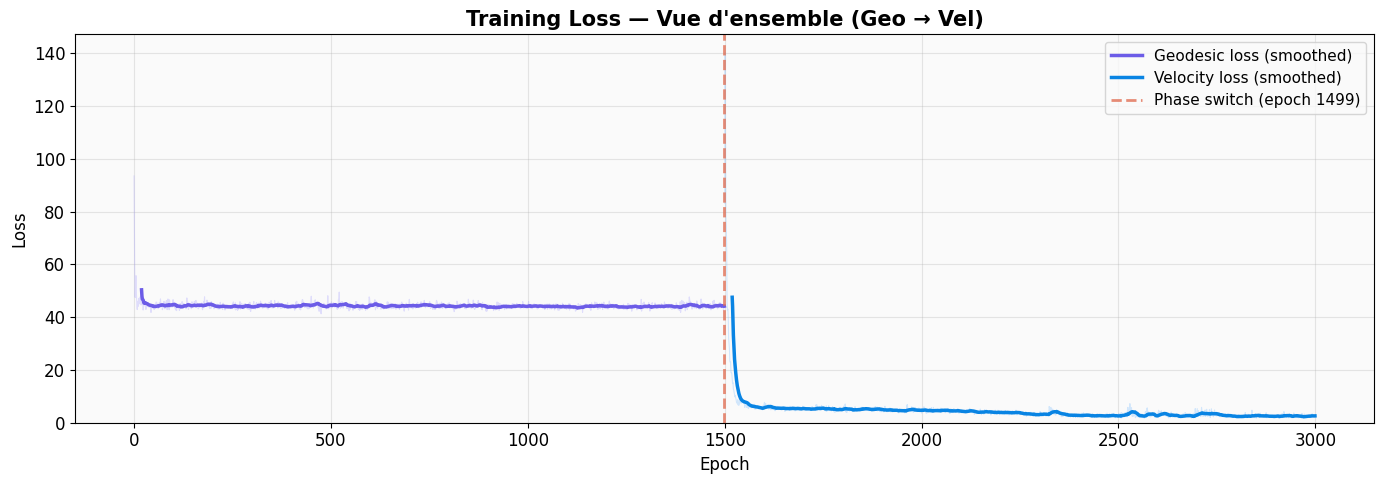

In [7]:
# ============================================================
# 3b. Vue d'ensemble : Geo + Vel loss combinée
# ============================================================

fig, ax = plt.subplots(1, 1, figsize=(14, 5))

# Plot geo loss
ax.plot(geo_loss['epoch'], geo_loss['train_geonet/loss'],
        alpha=0.3, linewidth=0.8, color='#a29bfe')
if len(geo_loss) > 20:
    rolling_geo = geo_loss['train_geonet/loss'].rolling(window=20).mean()
    ax.plot(geo_loss['epoch'], rolling_geo, linewidth=2.5,
            color='#6c5ce7', label='Geodesic loss (smoothed)')

# Plot vel loss
ax.plot(vel_loss['epoch'], vel_loss['train_vel/loss'],
        alpha=0.3, linewidth=0.8, color='#74b9ff')
if len(vel_loss) > 20:
    rolling_vel = vel_loss['train_vel/loss'].rolling(window=20).mean()
    ax.plot(vel_loss['epoch'], rolling_vel, linewidth=2.5,
            color='#0984e3', label='Velocity loss (smoothed)')

# Mark phase transition
transition_epoch = geo_loss['epoch'].iloc[-1]
ax.axvline(x=transition_epoch, color='#e17055', linestyle='--', linewidth=2,
           alpha=0.8, label=f'Phase switch (epoch {int(transition_epoch)})')

ax.set_xlabel('Epoch')
ax.set_ylabel('Loss')
ax.set_title('Training Loss — Vue d\'ensemble (Geo → Vel)',
             fontsize=15, fontweight='bold')
ax.legend(fontsize=11)
ax.set_ylim(bottom=0)
plt.tight_layout()
plt.show()


---

## 4. Trajectoires prédites vs Ground Truth (rollout autoregressif)

On intègre le velocity net de manière **autorégressive** : le point de départ du premier intervalle est la position réelle à $t_0$, puis chaque intervalle suivant utilise comme départ le **point prédit** à la fin de l'intervalle précédent. Cela reflète le vrai comportement en production — le modèle n'a **jamais accès aux positions cibles**.

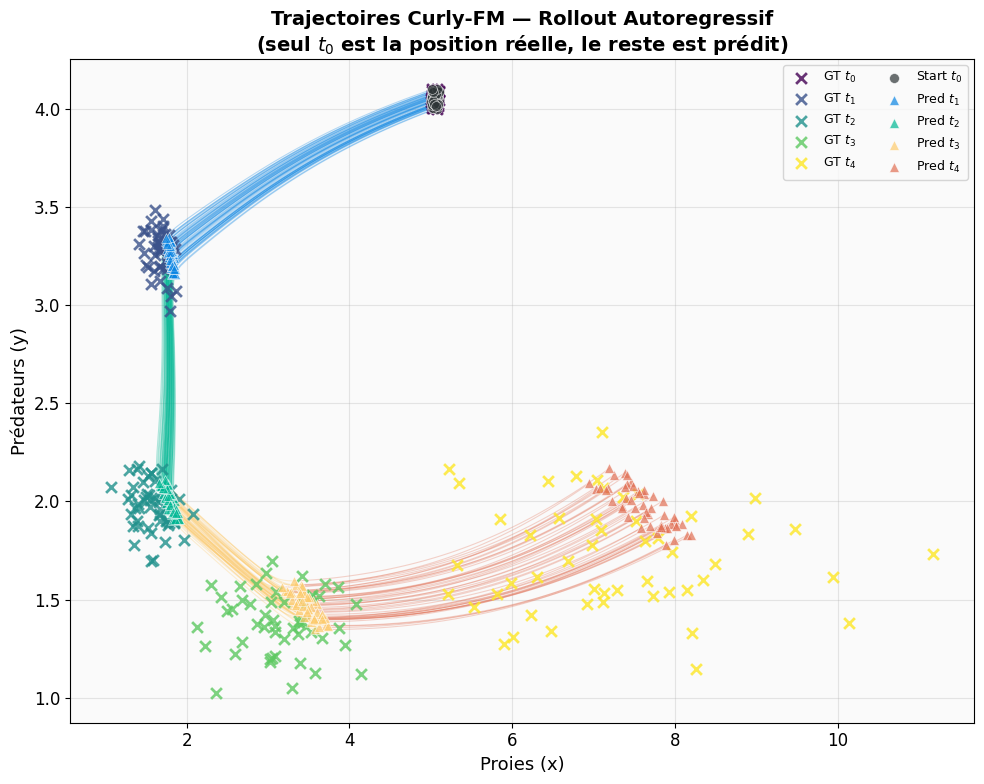


Erreur moyenne aux endpoints (autoregressive) :
  t0 -> t1 : 0.1856
  t1 -> t2 : 0.3035


  t2 -> t3 : 0.5435
  t3 -> t4 : 1.2244


In [8]:
# ============================================================
# 4. Trajectoires predites — rollout autoregressif, plot unique
# ============================================================
positions_t = torch.tensor(positions, dtype=torch.float32)
n_timesteps = positions.shape[1]
n_particles = min(50, positions.shape[0])

fig, ax = plt.subplots(1, 1, figsize=(10, 8))

# Colors per interval
interval_colors = ['#0984e3', '#00b894', '#fdcb6e', '#e17055']
snapshot_colors = plt.cm.viridis(np.linspace(0, 1, n_timesteps))

# Autoregressive rollout: start from real x0, then use predicted endpoints
x_current = positions_t[:n_particles, 0, :]  # real initial positions

all_trajectories = []  # store for each interval
all_endpoints = [x_current.numpy().copy()]

for ti in range(n_timesteps - 1):
    x_target_gt = positions_t[:n_particles, ti + 1, :]

    # ODE integration from current (predicted) position
    node = NeuralODE(
        torch_wrapper(vel_net), solver='dopri5', sensitivity='adjoint',
        atol=1e-4, rtol=1e-4
    )
    # Map this interval [t_start, t_end] from the original timesteps
    t_start = ti / (n_timesteps - 1)
    t_end = (ti + 1) / (n_timesteps - 1)
    with torch.no_grad():
        traj = node.trajectory(x_current, t_span=torch.linspace(t_start, t_end, 50))
    traj_np = traj.numpy()
    all_trajectories.append(traj_np)

    # Plot trajectories for this interval
    for p in range(n_particles):
        ax.plot(traj_np[:, p, 0], traj_np[:, p, 1],
                color=interval_colors[ti % len(interval_colors)],
                alpha=0.3, linewidth=0.8)

    # Update current position = predicted endpoint (autoregressive!)
    x_current = traj[-1]
    all_endpoints.append(x_current.numpy().copy())

# Plot ground truth snapshots
for ti in range(n_timesteps):
    gt = positions_t[:n_particles, ti, :]
    ax.scatter(gt[:, 0].numpy(), gt[:, 1].numpy(),
               c=[snapshot_colors[ti]], s=60, zorder=5,
               marker='x', linewidths=2, alpha=0.8,
               label=f'GT $t_{ti}$')

# Plot predicted endpoints
for ti, ep in enumerate(all_endpoints):
    marker = 'o' if ti == 0 else '^'
    color = '#2d3436' if ti == 0 else interval_colors[(ti - 1) % len(interval_colors)]
    label = f'Start $t_0$' if ti == 0 else f'Pred $t_{ti}$'
    ax.scatter(ep[:, 0], ep[:, 1], c=color, s=50, zorder=6,
               marker=marker, alpha=0.7, edgecolors='white', linewidth=0.5,
               label=label)

ax.set_xlabel('Proies (x)', fontsize=13)
ax.set_ylabel('Prédateurs (y)', fontsize=13)
ax.set_title('Trajectoires Curly-FM — Rollout Autoregressif\n'
             '(seul $t_0$ est la position réelle, le reste est prédit)',
             fontsize=14, fontweight='bold')
ax.legend(fontsize=9, loc='best', ncol=2)
plt.tight_layout()
plt.show()

# Compute endpoint errors
print('\nErreur moyenne aux endpoints (autoregressive) :')
x_current = positions_t[:n_particles, 0, :]
for ti in range(n_timesteps - 1):
    x_target = positions_t[:n_particles, ti + 1, :]
    node = NeuralODE(
        torch_wrapper(vel_net), solver='dopri5', sensitivity='adjoint',
        atol=1e-4, rtol=1e-4
    )
    t_start = ti / (n_timesteps - 1)
    t_end = (ti + 1) / (n_timesteps - 1)
    with torch.no_grad():
        traj = node.trajectory(x_current, t_span=torch.linspace(t_start, t_end, 2))
    x_current = traj[-1]
    endpoint_err = torch.norm(x_current - x_target, dim=-1).mean().item()
    print(f'  t{ti} -> t{ti+1} : {endpoint_err:.4f}')


---

## 5. Espace de phase + Champ de vitesses appris

On affiche le **champ de vitesses appris** par le velocity net sur une grille dans l'espace de phase, superposé aux positions réelles des particules.

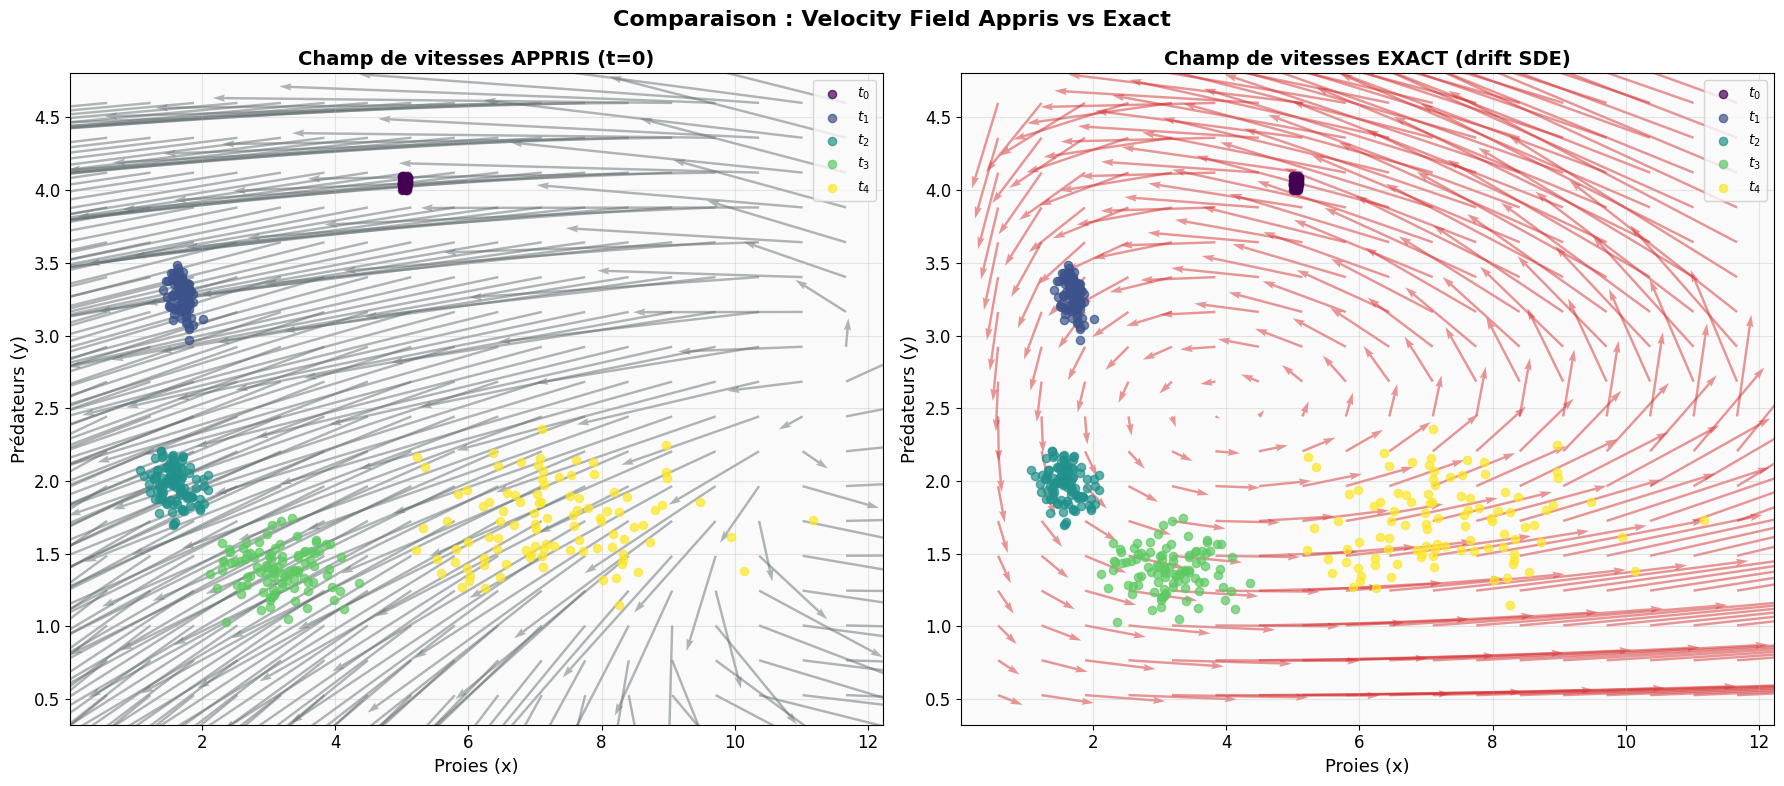

In [9]:
# ============================================================
# 5. Phase space + velocity field appris
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(18, 8))

# --- 5a: Velocity field appris ---
ax = axes[0]
colors_t = plt.cm.viridis(np.linspace(0, 1, n_timesteps))
for ti in range(n_timesteps):
    ax.scatter(positions[:, ti, 0], positions[:, ti, 1],
               c=[colors_t[ti]], s=35, alpha=0.7, label=f'$t_{ti}$', zorder=3)

# Grille pour le velocity field
x_range = [positions[:, :, 0].min() - 0.5, positions[:, :, 0].max() + 0.5]
y_range = [positions[:, :, 1].min() - 0.5, positions[:, :, 1].max() + 0.5]
grid_n = 18
xx, yy = np.meshgrid(np.linspace(x_range[0], x_range[1], grid_n),
                     np.linspace(y_range[0], y_range[1], grid_n))
grid_points = torch.tensor(np.stack([xx.flatten(), yy.flatten()], axis=-1), dtype=torch.float32)

with torch.no_grad():
    t_grid = torch.zeros(grid_points.shape[0], 1)
    # vel_net expects [x, t] concatenated, via forward(x) where x = [pos, t]
    v_grid = vel_net(torch.cat([grid_points, t_grid], dim=-1)).numpy()

ax.quiver(grid_points[:, 0], grid_points[:, 1], v_grid[:, 0], v_grid[:, 1],
          alpha=0.5, color='#636e72', scale=30, width=0.003)

ax.set_xlabel('Proies (x)', fontsize=13)
ax.set_ylabel('Prédateurs (y)', fontsize=13)
ax.set_title('Champ de vitesses APPRIS (t=0)', fontsize=14, fontweight='bold')
ax.legend(fontsize=10)

# --- 5b: Velocity field exact pour comparaison ---
ax = axes[1]
for ti in range(n_timesteps):
    ax.scatter(positions[:, ti, 0], positions[:, ti, 1],
               c=[colors_t[ti]], s=35, alpha=0.7, label=f'$t_{ti}$', zorder=3)

# Velocite exacte sur la meme grille
v_exact = lotka_volterra_drift(grid_points, dt=2.0).numpy()

ax.quiver(grid_points[:, 0], grid_points[:, 1], v_exact[:, 0], v_exact[:, 1],
          alpha=0.5, color='#d63031', scale=30, width=0.003)

ax.set_xlabel('Proies (x)', fontsize=13)
ax.set_ylabel('Prédateurs (y)', fontsize=13)
ax.set_title('Champ de vitesses EXACT (drift SDE)', fontsize=14, fontweight='bold')
ax.legend(fontsize=10)

plt.suptitle('Comparaison : Velocity Field Appris vs Exact',
             fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()


---

## 6. Résumé des métriques de training

Récapitulatif des performances du modèle à travers les deux phases d'entraînement.

In [10]:
# ============================================================
# 6. Résumé des métriques de training
# ============================================================

print('=' * 70)
print(f'{"Phase":<20} {"Loss initiale":>15} {"Loss finale":>15} {"Reduction":>12}')
print('=' * 70)

geo_init = geo_loss["train_geonet/loss"].iloc[0]
geo_final = geo_loss["train_geonet/loss"].iloc[-1]
vel_init = vel_loss["train_vel/loss"].iloc[0]
vel_final = vel_loss["train_vel/loss"].iloc[-1]

print(f'{"Geodesic (Stage 1)":<20} {geo_init:>15.3f} {geo_final:>15.3f} {geo_init/geo_final:>11.1f}x')
print(f'{"Velocity (Stage 2)":<20} {vel_init:>15.3f} {vel_final:>15.3f} {vel_init/vel_final:>11.1f}x')
print('=' * 70)

print(f'\nTotal epochs       : {int(df["epoch"].max())}')
print(f'Stage 1 (Geo)      : epochs 0-{int(geo_loss["epoch"].iloc[-1])}')
print(f'Stage 2 (Vel)      : epochs {int(vel_loss["epoch"].iloc[0])}-{int(vel_loss["epoch"].iloc[-1])}')


Phase                  Loss initiale     Loss finale    Reduction
Geodesic (Stage 1)            93.518          44.255         2.1x
Velocity (Stage 2)            83.163           2.680        31.0x

Total epochs       : 2999
Stage 1 (Geo)      : epochs 0-1499
Stage 2 (Vel)      : epochs 1500-2999


---

## Prochaines etapes

| Tache | Statut | Bloqueur |
|---|---|---|
| Lotka-Volterra (Stage 1 + 2) | **FAIT** | — |
| Repressilator | En attente | Donnees `repr_train` pas encore fournies |
| Petal | En attente | References/donnees pas encore fournies |

